In [6]:

# Task 2: Overfitting Analysis
# Step 2.0: Load Dataset

import pandas as pd
import numpy as np
from pathlib import Path

# Load the original dataset
file_path = Path("../data/fulldata.csv")
df = pd.read_csv(file_path)

# Basic information
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (27425, 15)

Columns:
['State', 'Strata', 'Sex', 'Age', 'Ethnic_Group', 'Citizenship', 'Marital_Status', 'Educational_Attainment', 'Highest_Certificate_Obtained', 'Field_of_Study', 'Occupation_2D', 'Industry_2D', 'G8_Total_salaries_and_wages', 'G14_Total_salaries_and_wages_includes_overtime', 'Weight']


,State,Strata,Sex,Age,Ethnic_Group,Citizenship,Marital_Status,Educational_Attainment,Highest_Certificate_Obtained,Field_of_Study,Occupation_2D,Industry_2D,G8_Total_salaries_and_wages,G14_Total_salaries_and_wages_includes_overtime,Weight
0,1,1,1,58,2,1,3,3,3,NaN,71,41,1520.0,1520.0,397.718282
1,12,2,1,64,1,1,2,4,4,NaN,12,46,3801.0,3801.0,48.357456
2,10,1,2,56,2,1,2,3,3,NaN,72,5,2930.0,2930.0,1225.996724
3,11,1,2,28,2,1,2,3,3,NaN,41,64,2971.0,2971.0,1201.312758
4,10,1,2,28,1,1,2,4,6,3.0,41,69,2034.0,2034.0,1460.804624


In [7]:

# Step 2.0.2: Restore Week 4 Recoding

df_recoded = df.drop(columns=[
    "Field_of_Study",
    "Highest_Certificate_Obtained",
    "Citizenship",
    "G14_Total_salaries_and_wages_includes_overtime"
]).copy()

# Occupation Recoding (MASCO)
occupation_mapping = {
    "0": "Armed Forces",
    "1": "Managers",
    "2": "Professionals",
    "3": "Technicians and Associate Professionals",
    "4": "Clerical Support Workers",
    "5": "Service and Sales Workers",
    "6": "Skilled Agricultural Workers",
    "7": "Craft and Related Trades Workers",
    "8": "Plant and Machine Operators",
    "9": "Elementary Occupations"
}

occupation_codes = (
    df_recoded["Occupation_2D"]
    .astype(int).astype(str).str.zfill(2)
)

df_recoded["Occupation_Group"] = (
    occupation_codes.str[0]
    .map(occupation_mapping)
    .astype("category")
)

# Industry Recoding (MSIC)
industry_ranges = {
    "A": [1, 2, 3],
    "B": list(range(5, 10)),
    "C": list(range(10, 34)),
    "D": [35],
    "E": [36, 37, 38, 39],
    "F": [41, 42, 43],
    "G": [45, 46, 47],
    "H": [49, 50, 51, 52, 53],
    "I": [55, 56],
    "J": list(range(58, 64)),
    "K": [64, 65, 66],
    "L": [68],
    "M": list(range(69, 76)),
    "N": list(range(77, 83)),
    "O": [84],
    "P": [85],
    "Q": [86, 87, 88],
    "R": [90, 91, 92, 93],
    "S": [94, 95, 96],
    "T": [97, 98],
    "U": [99]
}

industry_mapping = {
    str(code).zfill(2): section
    for section, codes in industry_ranges.items()
    for code in codes
}

industry_codes = (
    df_recoded["Industry_2D"]
    .astype(int).astype(str).str.zfill(2)
)

df_recoded["Industry_Section"] = (
    industry_codes.map(industry_mapping)
    .astype("category")
)

print("Occupation Groups:",
      df_recoded["Occupation_Group"].nunique())
print("Industry Sections:",
      df_recoded["Industry_Section"].nunique())
print("Unmapped Occupations:",
      df_recoded["Occupation_Group"].isna().sum())
print("Unmapped Industries:",
      df_recoded["Industry_Section"].isna().sum())


Occupation Groups: 10
Industry Sections: 19
Unmapped Occupations: 0
Unmapped Industries: 0


In [8]:

# Step 2.0.3: Model Preparation

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

feature_cols = [
    "State", "Strata", "Sex", "Age",
    "Ethnic_Group", "Marital_Status",
    "Educational_Attainment",
    "Occupation_Group", "Industry_Section"
]

target_col = "G8_Total_salaries_and_wages"

X = df_recoded[feature_cols].copy()
y = df_recoded[target_col].copy()

# Restore categorical types
nominal_features = [
    "State", "Strata", "Sex",
    "Ethnic_Group", "Marital_Status",
    "Occupation_Group", "Industry_Section"
]

for col in nominal_features:
    X[col] = X[col].astype("category")

X["Educational_Attainment"] = pd.Categorical(
    X["Educational_Attainment"],
    categories=[1, 2, 3, 4],
    ordered=True
)

# Check data before modelling
assert X.notna().all().all()
assert y.notna().all()
assert (y > 0).all()
assert "G14_Total_salaries_and_wages_includes_overtime" not in X.columns

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Same preprocessing as Week 4
preprocessor = ColumnTransformer([
    ("nominal",
     OneHotEncoder(handle_unknown="ignore"),
     nominal_features),
    ("ordinal",
     OrdinalEncoder(categories=[[1, 2, 3, 4]]),
     ["Educational_Attainment"]),
    ("numerical", "passthrough", ["Age"])
])

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("X_train:", X_train_encoded.shape)
print("X_test:", X_test_encoded.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (21940, 59)
X_test: (5485, 59)
y_train: (21940,)
y_test: (5485,)


In [9]:

# Step 2.1: Decision Tree Regression
# Overfitting Analysis

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import pandas as pd
import numpy as np

# Initialize Decision Tree
dt_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)

# Train the model
dt_model.fit(X_train_encoded, y_train)

# Predictions
y_train_pred_dt = dt_model.predict(X_train_encoded)
y_test_pred_dt = dt_model.predict(X_test_encoded)

# Evaluate training and testing performance
dt_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_dt),
        mean_absolute_error(y_test, y_test_pred_dt)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_dt)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_dt))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_dt),
        r2_score(y_test, y_test_pred_dt)
    ]
})

display(dt_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,841.6314,1543.8536,0.6128
1,Testing,900.6396,1610.2828,0.5325


In [10]:

# Step 2.2: Random Forest Regression
# Overfitting Analysis

from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

# Predictions
y_train_pred_rf = rf_model.predict(X_train_encoded)
y_test_pred_rf = rf_model.predict(X_test_encoded)

# Evaluate performance
rf_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_rf),
        mean_absolute_error(y_test, y_test_pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_rf))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_rf),
        r2_score(y_test, y_test_pred_rf)
    ]
})

display(rf_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,817.0047,1538.3099,0.6156
1,Testing,854.6513,1510.3141,0.5887


In [11]:

# Step 2.3.1: Gradient Boosting Regression
# Overfitting Analysis

from sklearn.ensemble import GradientBoostingRegressor

# Initialize Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    loss="squared_error",
    random_state=42
)

# Train the model
gb_model.fit(X_train_encoded, y_train)

# Predictions
y_train_pred_gb = gb_model.predict(X_train_encoded)
y_test_pred_gb = gb_model.predict(X_test_encoded)

# Evaluate performance
gb_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_gb),
        mean_absolute_error(y_test, y_test_pred_gb)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_gb)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_gb))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_gb),
        r2_score(y_test, y_test_pred_gb)
    ]
})

display(gb_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,843.5081,1493.6191,0.6376
1,Testing,859.6909,1540.2725,0.5723


In [12]:

# Step 2.3.2: XGBoost Regression
# Overfitting Analysis

from xgboost import XGBRegressor

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_encoded, y_train)

# Predictions
y_train_pred_xgb = xgb_model.predict(X_train_encoded)
y_test_pred_xgb = xgb_model.predict(X_test_encoded)

# Evaluate performance
xgb_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_xgb),
        mean_absolute_error(y_test, y_test_pred_xgb)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_xgb)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_xgb))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_xgb),
        r2_score(y_test, y_test_pred_xgb)
    ]
})

display(xgb_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,846.5979,1527.1197,0.6211
1,Testing,853.0396,1512.5199,0.5875


In [13]:

# Step 2.3.3: AdaBoost Regression
# Overfitting Analysis

from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

# Initialize AdaBoost
ada_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ),
    n_estimators=150,
    learning_rate=0.05,
    loss="linear",
    random_state=42
)

# Train the model
ada_model.fit(X_train_encoded, y_train)

# Predictions
y_train_pred_ada = ada_model.predict(X_train_encoded)
y_test_pred_ada = ada_model.predict(X_test_encoded)

# Evaluate performance
ada_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_ada),
        mean_absolute_error(y_test, y_test_pred_ada)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_ada)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_ada))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_ada),
        r2_score(y_test, y_test_pred_ada)
    ]
})

display(ada_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,1435.4820,1956.0455,0.3784
1,Testing,1419.5514,1961.3667,0.3064


In [15]:

# Step 2.5: CatBoost Regression
# Overfitting Analysis

from catboost import CatBoostRegressor

# Define categorical features
cat_features = [
    "State",
    "Strata",
    "Sex",
    "Ethnic_Group",
    "Marital_Status",
    "Occupation_Group",
    "Industry_Section"
]

# Prepare data for CatBoost
X_train_cat = X_train.copy()
X_test_cat = X_test.copy()

# Convert categorical values to strings
for col in cat_features:
    X_train_cat[col] = X_train_cat[col].astype(str)
    X_test_cat[col] = X_test_cat[col].astype(str)

# Keep education as an ordered numerical variable
X_train_cat["Educational_Attainment"] = (
    X_train_cat["Educational_Attainment"].astype(int)
)
X_test_cat["Educational_Attainment"] = (
    X_test_cat["Educational_Attainment"].astype(int)
)

# Initialize CatBoost
cat_model = CatBoostRegressor(
    iterations=400,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

# Train the model
cat_model.fit(
    X_train_cat,
    y_train,
    cat_features=cat_features
)

# Predictions
y_train_pred_cat = cat_model.predict(X_train_cat)
y_test_pred_cat = cat_model.predict(X_test_cat)

# Evaluate performance
cat_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_cat),
        mean_absolute_error(y_test, y_test_pred_cat)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_cat)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_cat))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_cat),
        r2_score(y_test, y_test_pred_cat)
    ]
})

display(cat_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,787.0232,1462.0657,0.6527
1,Testing,811.0146,1463.4648,0.6139


In [16]:

# Step 2.6: Ridge Regression
# Overfitting Analysis

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Initialize Ridge Regression
ridge_model = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("ridge", Ridge(
        alpha=10.0,
        solver="lsqr"
    ))
])

# Train the model
ridge_model.fit(X_train_encoded, y_train)

# Predictions
y_train_pred_ridge = ridge_model.predict(X_train_encoded)
y_test_pred_ridge = ridge_model.predict(X_test_encoded)

# Evaluate performance
ridge_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_ridge),
        mean_absolute_error(y_test, y_test_pred_ridge)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_ridge))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_ridge),
        r2_score(y_test, y_test_pred_ridge)
    ]
})

display(ridge_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,966.0420,1721.5963,0.5185
1,Testing,954.8697,1593.8911,0.5420


In [18]:

# Step 2.4: LightGBM Regression
# Overfitting Analysis

from lightgbm import LGBMRegressor

# Initialize LightGBM
lgbm_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=20,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train the model
lgbm_model.fit(X_train_encoded, y_train)

# Predictions
y_train_pred_lgbm = lgbm_model.predict(X_train_encoded)
y_test_pred_lgbm = lgbm_model.predict(X_test_encoded)

# Evaluate performance
lgbm_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_lgbm),
        mean_absolute_error(y_test, y_test_pred_lgbm)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_lgbm)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_lgbm))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_lgbm),
        r2_score(y_test, y_test_pred_lgbm)
    ]
})

display(lgbm_results.round(4))


,Dataset,MAE,RMSE,R2
0,Training,796.7925,1506.5576,0.6313
1,Testing,818.9561,1461.3186,0.6150


In [19]:

# Step 2.7.1: Decision Tree Complexity Analysis
# Unrestricted vs Restricted Decision Tree

from sklearn.tree import DecisionTreeRegressor

# 1. Train an unrestricted Decision Tree
dt_full_model = DecisionTreeRegressor(
    random_state=42
)

dt_full_model.fit(X_train_encoded, y_train)

# 2. Make predictions
y_train_pred_dt_full = dt_full_model.predict(
    X_train_encoded
)

y_test_pred_dt_full = dt_full_model.predict(
    X_test_encoded
)

# 3. Evaluate performance
dt_full_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_dt_full),
        mean_absolute_error(y_test, y_test_pred_dt_full)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_dt_full)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_dt_full))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_dt_full),
        r2_score(y_test, y_test_pred_dt_full)
    ]
})

# 4. Compare both Decision Trees
dt_comparison = pd.concat([
    dt_full_results.assign(
        Model="Unrestricted Decision Tree"
    ),
    dt_results.assign(
        Model="Restricted Decision Tree"
    )
], ignore_index=True)

dt_comparison = dt_comparison[
    ["Model", "Dataset", "MAE", "RMSE", "R2"]
]

print("Decision Tree Performance Comparison")
display(dt_comparison.round(4))

# 5. Compare tree complexity
print("\nTree Complexity:")

print(
    "Unrestricted Tree Depth:",
    dt_full_model.get_depth()
)

print(
    "Restricted Tree Depth:",
    dt_model.get_depth()
)

print(
    "Unrestricted Tree Leaves:",
    dt_full_model.get_n_leaves()
)

print(
    "Restricted Tree Leaves:",
    dt_model.get_n_leaves()
)


Decision Tree Performance Comparison


,Model,Dataset,MAE,RMSE,R2
0,Unrestricted Decision Tree,Training,84.9293,359.5204,0.9790
1,Unrestricted Decision Tree,Testing,1017.8145,1930.2676,0.3282
2,Restricted Decision Tree,Training,841.6314,1543.8536,0.6128
3,Restricted Decision Tree,Testing,900.6396,1610.2828,0.5325



Tree Complexity:
Unrestricted Tree Depth: 50
Restricted Tree Depth: 10
Unrestricted Tree Leaves: 19104
Restricted Tree Leaves: 324


In [20]:

# Step 2.7.2: 5-Fold Cross-validation
# Decision Tree Complexity Analysis

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Define cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Models for comparison
cv_dt_models = {
    "Unrestricted DT": dt_full_model,
    "Restricted DT": dt_model
}

# Evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_records = []

for name, model in cv_dt_models.items():

    print("Running 5-Fold CV:", name)

    # Fit preprocessing separately within each fold
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )

    cv_records.append({
        "Model": name,
        "Train MAE": -scores["train_MAE"].mean(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV MAE SD": scores["test_MAE"].std(),
        "Train RMSE": -scores["train_RMSE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "Train R2": scores["train_R2"].mean(),
        "CV R2": scores["test_R2"].mean(),
        "CV R2 SD": scores["test_R2"].std()
    })

cv_dt_results = pd.DataFrame(cv_records)

display(cv_dt_results.round(4))


Running 5-Fold CV: Unrestricted DT
Running 5-Fold CV: Restricted DT


,Model,Train MAE,CV MAE,CV MAE SD,Train RMSE,CV RMSE,Train R2,CV R2,CV R2 SD
0,Unrestricted DT,72.3264,1032.6948,23.6648,330.1148,2174.7582,0.9823,0.2162,0.1636
1,Restricted DT,839.6349,898.6963,13.5800,1550.8784,1705.8745,0.6092,0.5265,0.0340


In [21]:

# Step 2.7.3: Seven-Model Cross-validation

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from catboost import CatBoostRegressor

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Six models using Week 4 preprocessing
cv_models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model
}

cv_records_all = []

def save_cv_results(name, scores):
    return {
        "Model": name,
        "Train MAE": -scores["train_MAE"].mean(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV MAE SD": scores["test_MAE"].std(),
        "Train R2": scores["train_R2"].mean(),
        "CV R2": scores["test_R2"].mean(),
        "CV R2 SD": scores["test_R2"].std()
    }

# 1. Cross-validation for six models
for name, model in cv_models.items():

    print("Running CV:", name)

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    cv_records_all.append(
        save_cv_results(name, scores)
    )

# 2. CatBoost with native categorical features
print("Running CV: CatBoost")

cat_cv_model = CatBoostRegressor(
    iterations=400,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    cat_features=cat_features,
    verbose=False,
    allow_writing_files=False
)

cat_scores = cross_validate(
    cat_cv_model,
    X_train_cat,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

cv_records_all.append(
    save_cv_results("CatBoost", cat_scores)
)

# 3. Final comparison
cv_all_results = pd.DataFrame(cv_records_all)

cv_all_results["MAE Gap"] = (
    cv_all_results["CV MAE"]
    - cv_all_results["Train MAE"]
)

cv_all_results = cv_all_results.sort_values(
    "CV MAE"
).reset_index(drop=True)

display(cv_all_results.round(3))


Running CV: Decision Tree
Running CV: Random Forest
Running CV: AdaBoost
Running CV: Gradient Boosting
Running CV: XGBoost
Running CV: LightGBM
Running CV: CatBoost


RuntimeError: Cannot clone object CatBoostRegressor(allow_writing_files=False, cat_features=['State', 'Strata', 'Sex', 'Ethnic_Group', 'Marital_Status', 'Occupation_Group', 'Industry_Section'], depth=6, iterations=400, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=False), as the constructor either does not set or modifies parameter cat_features

In [23]:

# Step 2.7.3: CatBoost 5-Fold CV (Fixed)

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import pandas as pd

train_mae_scores = []
val_mae_scores = []
train_r2_scores = []
val_r2_scores = []

# Use the same 5 folds as other models
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train_cat), start=1
):

    # Split training and validation data
    X_fit = X_train_cat.iloc[train_idx]
    X_val = X_train_cat.iloc[val_idx]

    y_fit = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    # Create a fresh CatBoost model
    model = CatBoostRegressor(
        iterations=400,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    # Train using the categorical features
    model.fit(
        X_fit,
        y_fit,
        cat_features=cat_features
    )

    # Predictions
    pred_train = model.predict(X_fit)
    pred_val = model.predict(X_val)

    # Evaluation
    train_mae_scores.append(
        mean_absolute_error(y_fit, pred_train)
    )
    val_mae_scores.append(
        mean_absolute_error(y_val, pred_val)
    )
    train_r2_scores.append(
        r2_score(y_fit, pred_train)
    )
    val_r2_scores.append(
        r2_score(y_val, pred_val)
    )

    print(f"Fold {fold} completed")

# Save CatBoost CV results
cat_cv_result = {
    "Model": "CatBoost",
    "Train MAE": np.mean(train_mae_scores),
    "CV MAE": np.mean(val_mae_scores),
    "CV MAE SD": np.std(val_mae_scores),
    "Train R2": np.mean(train_r2_scores),
    "CV R2": np.mean(val_r2_scores),
    "CV R2 SD": np.std(val_r2_scores)
}

# Add CatBoost without duplicating it
cv_records_all = [
    r for r in cv_records_all
    if r["Model"] != "CatBoost"
]

cv_records_all.append(cat_cv_result)

# Final seven-model comparison
cv_all_results = pd.DataFrame(cv_records_all)

cv_all_results["MAE Gap"] = (
    cv_all_results["CV MAE"]
    - cv_all_results["Train MAE"]
)

cv_all_results = cv_all_results.sort_values(
    "CV MAE"
).reset_index(drop=True)

display(cv_all_results.round(3))


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


,Model,Train MAE,CV MAE,CV MAE SD,Train R2,CV R2,CV R2 SD,MAE Gap
0,CatBoost,777.008,809.307,9.278,0.676,0.597,0.044,32.299
1,LightGBM,794.377,825.073,9.893,0.635,0.593,0.046,30.696
2,Random Forest,817.896,860.809,11.213,0.617,0.568,0.043,42.913
3,XGBoost,843.424,861.469,10.260,0.627,0.572,0.044,18.045
4,Gradient Boosting,841.777,862.299,10.134,0.640,0.569,0.038,20.522
5,Decision Tree,839.635,898.696,13.580,0.609,0.526,0.034,59.061
6,AdaBoost,1385.353,1395.499,29.495,0.403,0.336,0.025,10.147


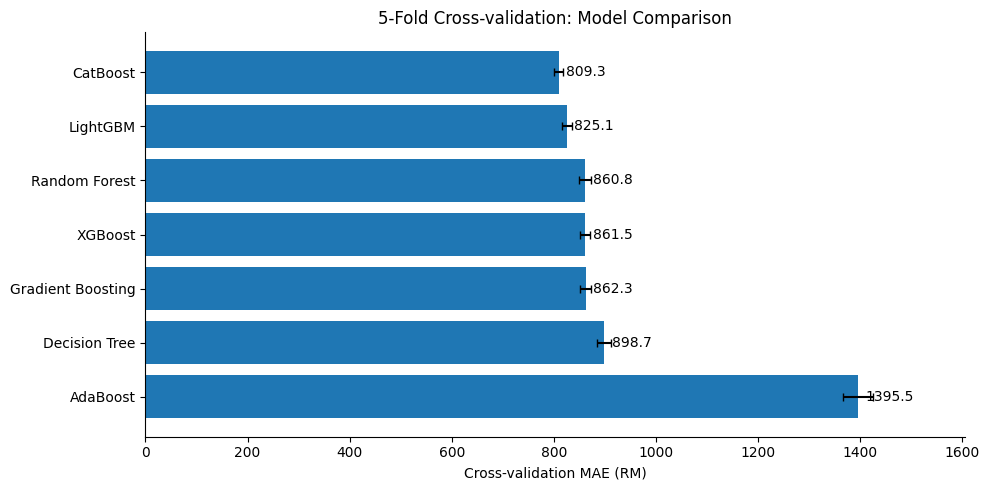

In [24]:

# Step 2.7.4: Cross-validation Performance Visualization

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare results
plot_df = cv_all_results.sort_values(
    "CV MAE",
    ascending=True
)

# Create figure
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_df["Model"],
    plot_df["CV MAE"],
    xerr=plot_df["CV MAE SD"],
    capsize=3
)

# Add MAE values
for bar, value in zip(bars, plot_df["CV MAE"]):
    ax.text(
        value + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}",
        va="center",
        fontsize=10
    )

ax.invert_yaxis()

ax.set_xlabel("Cross-validation MAE (RM)")
ax.set_title("5-Fold Cross-validation: Model Comparison")

ax.set_xlim(0, plot_df["CV MAE"].max() * 1.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save figure
output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "week5_cv_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


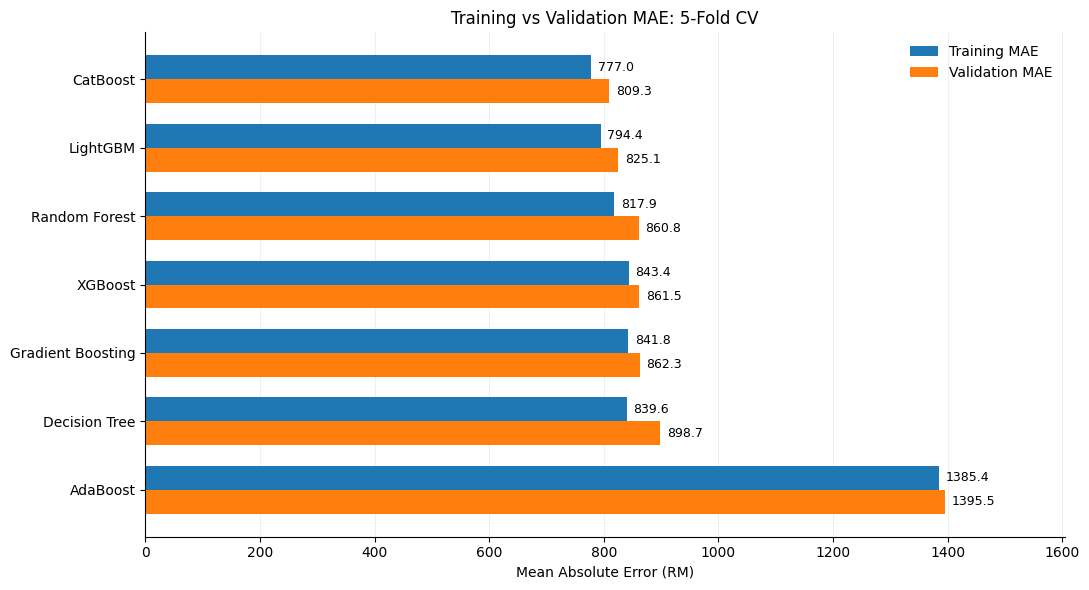

In [25]:

# Step 2.7.5: Training vs Validation MAE
# Overfitting Comparison

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Sort models by CV MAE
plot_df = cv_all_results.sort_values(
    "CV MAE"
).reset_index(drop=True)

y_pos = np.arange(len(plot_df))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

# Training MAE
bars_train = ax.barh(
    y_pos - bar_height / 2,
    plot_df["Train MAE"],
    height=bar_height,
    label="Training MAE"
)

# Validation MAE
bars_val = ax.barh(
    y_pos + bar_height / 2,
    plot_df["CV MAE"],
    height=bar_height,
    label="Validation MAE"
)

# Add values
for bars in [bars_train, bars_val]:
    for bar in bars:
        value = bar.get_width()
        ax.text(
            value + 12,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}",
            va="center",
            fontsize=9
        )

# Axis settings
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["Model"])
ax.invert_yaxis()

ax.set_xlabel("Mean Absolute Error (RM)")
ax.set_title(
    "Training vs Validation MAE: 5-Fold CV"
)

ax.set_xlim(
    0,
    plot_df["CV MAE"].max() * 1.15
)

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save figure
output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "week5_train_vs_cv_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Target,Mean,Median,Skewness
0,Original G8,3018.8894,2097.0000,4.5685
1,Log G8,7.7787,7.6483,0.4377


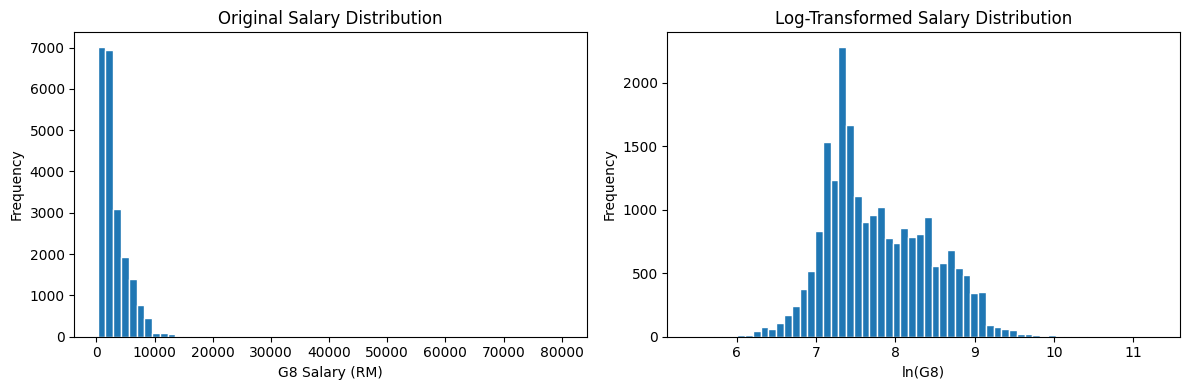

In [26]:

# Task 3: Log Transformation
# Step 3.1: Transform G8 Salary

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Check that salary values are positive
assert (y_train > 0).all()
assert (y_test > 0).all()

# Apply natural logarithm
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

# Compare distribution statistics
salary_summary = pd.DataFrame({
    "Target": ["Original G8", "Log G8"],
    "Mean": [y_train.mean(), y_train_log.mean()],
    "Median": [y_train.median(), y_train_log.median()],
    "Skewness": [y_train.skew(), y_train_log.skew()]
})

display(salary_summary.round(4))

# Compare distributions using training data
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_train, bins=60, edgecolor="white")
axes[0].set_title("Original Salary Distribution")
axes[0].set_xlabel("G8 Salary (RM)")
axes[0].set_ylabel("Frequency")

axes[1].hist(y_train_log, bins=60, edgecolor="white")
axes[1].set_title("Log-Transformed Salary Distribution")
axes[1].set_xlabel("ln(G8)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()

output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "week5_salary_log_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [27]:

# Step 3.2.1: Decision Tree with Log Salary

from sklearn.base import clone

# 1. Create a new Decision Tree with the same parameters
dt_log_model = clone(dt_model)

# 2. Train using log-transformed salary
dt_log_model.fit(X_train_encoded, y_train_log)

# 3. Predict log salary
train_pred_log = dt_log_model.predict(X_train_encoded)
test_pred_log = dt_log_model.predict(X_test_encoded)

# 4. Convert predictions back to RM
y_train_pred_dt_log = np.exp(train_pred_log)
y_test_pred_dt_log = np.exp(test_pred_log)

# 5. Evaluate on the original salary scale
dt_log_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_dt_log),
        mean_absolute_error(y_test, y_test_pred_dt_log)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_dt_log)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_dt_log))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_dt_log),
        r2_score(y_test, y_test_pred_dt_log)
    ]
})

# 6. Compare original and log target
dt_comparison_log = pd.concat([
    dt_results.assign(Target="Original G8"),
    dt_log_results.assign(Target="ln(G8)")
], ignore_index=True)

display(
    dt_comparison_log[
        ["Target", "Dataset", "MAE", "RMSE", "R2"]
    ].round(4)
)


,Target,Dataset,MAE,RMSE,R2
0,Original G8,Training,841.6314,1543.8536,0.6128
1,Original G8,Testing,900.6396,1610.2828,0.5325
2,ln(G8),Training,818.6391,1644.0686,0.5609
3,ln(G8),Testing,858.0583,1567.1472,0.5572


In [28]:

# Step 3.2.2: Log Transformation
# Retrain Five Models Using ln(G8)

from sklearn.base import clone

# Original models and their results
models_to_compare = {
    "Random Forest": (rf_model, rf_results),
    "AdaBoost": (ada_model, ada_results),
    "Gradient Boosting": (gb_model, gb_results),
    "XGBoost": (xgb_model, xgb_results),
    "LightGBM": (lgbm_model, lgbm_results)
}

# Store log-model results
log_results = {
    "Decision Tree": dt_log_results
}

log_fitted_models = {
    "Decision Tree": dt_log_model
}

comparison_records = []

for name, (original_model, original_result) in models_to_compare.items():

    print("Training log model:", name)

    # Same model parameters
    model = clone(original_model)

    # Train on ln(G8)
    model.fit(X_train_encoded, y_train_log)

    # Predict and convert back to RM
    train_pred = np.exp(
        model.predict(X_train_encoded)
    )

    test_pred = np.exp(
        model.predict(X_test_encoded)
    )

    # Calculate original-scale metrics
    log_result = pd.DataFrame({
        "Dataset": ["Training", "Testing"],
        "MAE": [
            mean_absolute_error(y_train, train_pred),
            mean_absolute_error(y_test, test_pred)
        ],
        "RMSE": [
            np.sqrt(mean_squared_error(y_train, train_pred)),
            np.sqrt(mean_squared_error(y_test, test_pred))
        ],
        "R2": [
            r2_score(y_train, train_pred),
            r2_score(y_test, test_pred)
        ]
    })

    # Save for later analysis
    log_results[name] = log_result
    log_fitted_models[name] = model

    # Compare testing performance
    original_test = original_result.iloc[1]
    log_test = log_result.iloc[1]

    comparison_records.append({
        "Model": name,
        "Original MAE": original_test["MAE"],
        "Log MAE": log_test["MAE"],
        "MAE Improvement": (
            original_test["MAE"] - log_test["MAE"]
        ),
        "Original RMSE": original_test["RMSE"],
        "Log RMSE": log_test["RMSE"],
        "Original R2": original_test["R2"],
        "Log R2": log_test["R2"]
    })

# Summary table
log_comparison_df = pd.DataFrame(comparison_records)

display(log_comparison_df.round(3))


Training log model: Random Forest
Training log model: AdaBoost
Training log model: Gradient Boosting
Training log model: XGBoost
Training log model: LightGBM


,Model,Original MAE,Log MAE,MAE Improvement,Original RMSE,Log RMSE,Original R2,Log R2
0,Random Forest,854.651,827.082,27.569,1510.314,1530.979,0.589,0.577
1,AdaBoost,1419.551,1066.293,353.258,1961.367,1772.859,0.306,0.433
2,Gradient Boosting,859.691,821.435,38.256,1540.272,1526.448,0.572,0.580
3,XGBoost,853.040,821.023,32.017,1512.520,1528.694,0.588,0.579
4,LightGBM,818.956,782.549,36.407,1461.319,1477.061,0.615,0.607


In [29]:

# Step 3.2.3: CatBoost with Log Salary

from catboost import CatBoostRegressor

# 1. Initialize with the same parameters
cat_log_model = CatBoostRegressor(
    iterations=400,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

# 2. Train using ln(G8)
cat_log_model.fit(
    X_train_cat,
    y_train_log,
    cat_features=cat_features
)

# 3. Predict log salary
train_pred_cat_log = cat_log_model.predict(
    X_train_cat
)

test_pred_cat_log = cat_log_model.predict(
    X_test_cat
)

# 4. Convert back to RM
y_train_pred_cat_log = np.exp(train_pred_cat_log)
y_test_pred_cat_log = np.exp(test_pred_cat_log)

# 5. Evaluate performance
cat_log_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, y_train_pred_cat_log),
        mean_absolute_error(y_test, y_test_pred_cat_log)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred_cat_log)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_cat_log))
    ],
    "R2": [
        r2_score(y_train, y_train_pred_cat_log),
        r2_score(y_test, y_test_pred_cat_log)
    ]
})

# 6. Store results for later comparison
log_results["CatBoost"] = cat_log_results
log_fitted_models["CatBoost"] = cat_log_model

# 7. Compare original and log salary
cat_comparison_log = pd.concat([
    cat_results.assign(Target="Original G8"),
    cat_log_results.assign(Target="ln(G8)")
], ignore_index=True)

display(
    cat_comparison_log[
        ["Target", "Dataset", "MAE", "RMSE", "R2"]
    ].round(4)
)


,Target,Dataset,MAE,RMSE,R2
0,Original G8,Training,787.0232,1462.0657,0.6527
1,Original G8,Testing,811.0146,1463.4648,0.6139
2,ln(G8),Training,742.9940,1544.1976,0.6126
3,ln(G8),Testing,765.8125,1449.5404,0.6212


In [30]:

# Step 3.3.1: Original G8 vs ln(G8)
# Seven-Model Performance Comparison

original_results = {
    "Decision Tree": dt_results,
    "Random Forest": rf_results,
    "AdaBoost": ada_results,
    "Gradient Boosting": gb_results,
    "XGBoost": xgb_results,
    "LightGBM": lgbm_results,
    "CatBoost": cat_results
}

# Verify all seven log models are available
assert set(original_results) == set(log_results)

comparison_records = []

for name in original_results:

    # Original target results
    original_test = original_results[name].loc[
        original_results[name]["Dataset"] == "Testing"
    ].iloc[0]

    # Log target results (back-transformed to RM)
    log_test = log_results[name].loc[
        log_results[name]["Dataset"] == "Testing"
    ].iloc[0]

    comparison_records.append({
        "Model": name,
        "Original MAE": original_test["MAE"],
        "Log MAE": log_test["MAE"],
        "MAE Improvement (%)": (
            (original_test["MAE"] - log_test["MAE"])
            / original_test["MAE"] * 100
        ),
        "Original RMSE": original_test["RMSE"],
        "Log RMSE": log_test["RMSE"],
        "RMSE Improvement": (
            original_test["RMSE"] - log_test["RMSE"]
        ),
        "Original R2": original_test["R2"],
        "Log R2": log_test["R2"]
    })

# Final comparison table
final_log_comparison = pd.DataFrame(
    comparison_records
)

final_log_comparison = final_log_comparison.sort_values(
    "Log MAE"
).reset_index(drop=True)

display(final_log_comparison.round(3))


,Model,Original MAE,Log MAE,MAE Improvement (%),Original RMSE,Log RMSE,RMSE Improvement,Original R2,Log R2
0,CatBoost,811.015,765.813,5.574,1463.465,1449.540,13.924,0.614,0.621
1,LightGBM,818.956,782.549,4.446,1461.319,1477.061,-15.743,0.615,0.607
2,XGBoost,853.040,821.023,3.753,1512.520,1528.694,-16.174,0.588,0.579
3,Gradient Boosting,859.691,821.435,4.450,1540.272,1526.448,13.824,0.572,0.580
4,Random Forest,854.651,827.082,3.226,1510.314,1530.979,-20.665,0.589,0.577
5,Decision Tree,900.640,858.058,4.728,1610.283,1567.147,43.136,0.533,0.557
6,AdaBoost,1419.551,1066.293,24.885,1961.367,1772.859,188.508,0.306,0.433


In [31]:

# Step 3.4.1: 5-Fold CV with ln(G8)
# Six models (excluding CatBoost)

from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from pathlib import Path
import numpy as np
import pandas as pd

log_cv_models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model
}

log_cv_records = []

output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

for name, base_model in log_cv_models.items():

    print("Running Log CV:", name, flush=True)

    # Preprocessing + log target transformation
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", TransformedTargetRegressor(
            regressor=clone(base_model),
            func=np.log,
            inverse_func=np.exp
        ))
    ])

    # Same 5 folds as Task 2
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    log_cv_records.append({
        "Model": name,
        "Train MAE": -scores["train_MAE"].mean(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV MAE SD": scores["test_MAE"].std(),
        "Train RMSE": -scores["train_RMSE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "Train R2": scores["train_R2"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

    # Save progress after each model
    pd.DataFrame(log_cv_records).to_csv(
        output_dir / "week5_log_cv_partial.csv",
        index=False
    )

    print(name, "completed", flush=True)

log_cv_six = pd.DataFrame(log_cv_records)

# Compare against original G8 cross-validation
original_cv = cv_all_results[
    ["Model", "CV MAE"]
].rename(columns={
    "CV MAE": "Original CV MAE"
})

log_cv_comparison = original_cv.merge(
    log_cv_six[["Model", "CV MAE"]],
    on="Model",
    how="inner"
).rename(columns={
    "CV MAE": "Log CV MAE"
})

log_cv_comparison["Improvement (RM)"] = (
    log_cv_comparison["Original CV MAE"]
    - log_cv_comparison["Log CV MAE"]
)

display(log_cv_comparison.round(3))


Running Log CV: Decision Tree
Decision Tree completed
Running Log CV: Random Forest
Random Forest completed
Running Log CV: AdaBoost
AdaBoost completed
Running Log CV: Gradient Boosting
Gradient Boosting completed
Running Log CV: XGBoost
XGBoost completed
Running Log CV: LightGBM
LightGBM completed


,Model,Original CV MAE,Log CV MAE,Improvement (RM)
0,LightGBM,825.073,786.984,38.089
1,Random Forest,860.809,833.031,27.778
2,XGBoost,861.469,828.181,33.288
3,Gradient Boosting,862.299,827.649,34.650
4,Decision Tree,898.696,866.174,32.523
5,AdaBoost,1395.499,1087.594,307.905


In [32]:

# Step 3.4.2: CatBoost 5-Fold CV with ln(G8)

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

cat_log_cv_records = []

# Use the same five folds
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train_cat), start=1
):

    # Split data within the training set
    X_fit = X_train_cat.iloc[train_idx]
    X_val = X_train_cat.iloc[val_idx]

    y_fit = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    # Log-transform training target only
    y_fit_log = np.log(y_fit)

    # Same CatBoost parameters
    model = CatBoostRegressor(
        iterations=400,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_fit,
        y_fit_log,
        cat_features=cat_features
    )

    # Convert log predictions back to RM
    pred_train = np.exp(model.predict(X_fit))
    pred_val = np.exp(model.predict(X_val))

    cat_log_cv_records.append({
        "Fold": fold,
        "Train MAE": mean_absolute_error(y_fit, pred_train),
        "CV MAE": mean_absolute_error(y_val, pred_val),
        "Train RMSE": np.sqrt(
            mean_squared_error(y_fit, pred_train)
        ),
        "CV RMSE": np.sqrt(
            mean_squared_error(y_val, pred_val)
        ),
        "Train R2": r2_score(y_fit, pred_train),
        "CV R2": r2_score(y_val, pred_val)
    })

    print(f"Fold {fold} completed")

# Summarize CatBoost CV
cat_log_cv_df = pd.DataFrame(cat_log_cv_records)

cat_log_cv_result = {
    "Model": "CatBoost",
    "Train MAE": cat_log_cv_df["Train MAE"].mean(),
    "CV MAE": cat_log_cv_df["CV MAE"].mean(),
    "CV MAE SD": cat_log_cv_df["CV MAE"].std(ddof=0),
    "Train RMSE": cat_log_cv_df["Train RMSE"].mean(),
    "CV RMSE": cat_log_cv_df["CV RMSE"].mean(),
    "Train R2": cat_log_cv_df["Train R2"].mean(),
    "CV R2": cat_log_cv_df["CV R2"].mean()
}

display(pd.DataFrame([cat_log_cv_result]).round(3))


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed


,Model,Train MAE,CV MAE,CV MAE SD,Train RMSE,CV RMSE,Train R2,CV R2
0,CatBoost,741.545,767.555,14.743,1534.278,1579.247,0.618,0.595


In [33]:

# Step 3.4.3: Final Original vs Log CV Comparison

# Combine all seven log CV results
log_cv_all = pd.DataFrame(
    log_cv_records + [cat_log_cv_result]
)

# Original G8 results
original_cv = cv_all_results[
    ["Model", "CV MAE", "CV R2"]
].rename(columns={
    "CV MAE": "Original CV MAE",
    "CV R2": "Original CV R2"
})

# Log G8 results
log_cv = log_cv_all[
    ["Model", "CV MAE", "CV R2"]
].rename(columns={
    "CV MAE": "Log CV MAE",
    "CV R2": "Log CV R2"
})

# Merge results
final_cv_comparison = original_cv.merge(
    log_cv,
    on="Model",
    validate="one_to_one"
)

assert len(final_cv_comparison) == 7

# Calculate improvements
final_cv_comparison["MAE Improvement"] = (
    final_cv_comparison["Original CV MAE"]
    - final_cv_comparison["Log CV MAE"]
)

final_cv_comparison["R2 Change"] = (
    final_cv_comparison["Log CV R2"]
    - final_cv_comparison["Original CV R2"]
)

# Sort by Log CV MAE
final_cv_comparison = final_cv_comparison.sort_values(
    "Log CV MAE"
).reset_index(drop=True)

display(final_cv_comparison.round(3))

# Save results
final_cv_comparison.to_csv(
    "../results/week5_original_vs_log_cv.csv",
    index=False
)


,Model,Original CV MAE,Original CV R2,Log CV MAE,Log CV R2,MAE Improvement,R2 Change
0,CatBoost,809.307,0.597,767.555,0.595,41.751,-0.003
1,LightGBM,825.073,0.593,786.984,0.582,38.089,-0.011
2,Gradient Boosting,862.299,0.569,827.649,0.556,34.650,-0.013
3,XGBoost,861.469,0.572,828.181,0.555,33.288,-0.017
4,Random Forest,860.809,0.568,833.031,0.553,27.778,-0.015
5,Decision Tree,898.696,0.526,866.174,0.528,32.523,0.001
6,AdaBoost,1395.499,0.336,1087.594,0.417,307.905,0.081


In [34]:

# Step 3.5.1: Income Group Error Analysis
# Original CatBoost vs Log CatBoost

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# 1. Define income thresholds using training data
p50, p90 = np.quantile(y_train, [0.50, 0.90])

print(f"Training P50: RM {p50:.2f}")
print(f"Training P90: RM {p90:.2f}")

# 2. Prepare test predictions
y_actual = np.asarray(y_test)

pred_original = np.asarray(y_test_pred_cat)
pred_log = np.asarray(y_test_pred_cat_log)

assert len(y_actual) == len(pred_original) == len(pred_log)

# 3. Assign income groups using actual test salaries
income_groups = pd.cut(
    y_actual,
    bins=[-np.inf, p50, p90, np.inf],
    labels=[
        "Low Income",
        "Middle Income",
        "High Income"
    ]
)

# 4. Create evaluation dataframe
error_df = pd.DataFrame({
    "Actual Salary": y_actual,
    "Original Prediction": pred_original,
    "Log Prediction": pred_log,
    "Income Group": income_groups
})

# 5. Calculate group-level metrics
group_records = []

for group, data in error_df.groupby(
    "Income Group", observed=True
):

    actual = data["Actual Salary"]
    original = data["Original Prediction"]
    log_pred = data["Log Prediction"]

    group_records.append({
        "Income Group": group,
        "N": len(data),
        "Mean Actual": actual.mean(),
        "Original MAE": mean_absolute_error(
            actual, original
        ),
        "Log MAE": mean_absolute_error(
            actual, log_pred
        ),
        "Original Bias": (original - actual).mean(),
        "Log Bias": (log_pred - actual).mean()
    })

group_summary = pd.DataFrame(group_records)

# 6. Compare MAE changes
group_summary["MAE Change"] = (
    group_summary["Log MAE"]
    - group_summary["Original MAE"]
)

display(group_summary.round(2))


Training P50: RM 2097.00
Training P90: RM 6155.10


,Income Group,N,Mean Actual,Original MAE,Log MAE,Original Bias,Log Bias,MAE Change
0,Low Income,2702,1453.77,475.74,359.26,378.10,248.95,-116.48
1,Middle Income,2275,3655.38,875.65,869.78,-43.19,-258.63,-5.87
2,High Income,508,8491.10,2304.84,2462.64,-1925.35,-2263.95,157.79


In [35]:

# Step 3.5.2: Relative Error & High-Salary Analysis

import numpy as np
import pandas as pd

# Define evaluation groups
groups = {
    "Low Income": error_df[
        error_df["Income Group"] == "Low Income"
    ],
    "Middle Income": error_df[
        error_df["Income Group"] == "Middle Income"
    ],
    "High Income": error_df[
        error_df["Income Group"] == "High Income"
    ],
    "Salary >= RM10000": error_df[
        error_df["Actual Salary"] >= 10000
    ]
}

records = []

for group_name, data in groups.items():

    actual = data["Actual Salary"].to_numpy()

    for model_name, pred_col in [
        ("Original CatBoost", "Original Prediction"),
        ("Log CatBoost", "Log Prediction")
    ]:

        predicted = data[pred_col].to_numpy()
        errors = predicted - actual

        records.append({
            "Income Group": group_name,
            "Model": model_name,
            "N": len(data),
            "Mean Actual": actual.mean(),
            "Mean Predicted": predicted.mean(),
            "MAE": np.abs(errors).mean(),
            "WAPE (%)": (
                np.abs(errors).sum()
                / actual.sum() * 100
            ),
            "Bias": errors.mean(),
            "Bias (%)": (
                errors.sum()
                / actual.sum() * 100
            )
        })

relative_error_df = pd.DataFrame(records)

display(relative_error_df.round(2))


,Income Group,Model,N,Mean Actual,Mean Predicted,MAE,WAPE (%),Bias,Bias (%)
0,Low Income,Original CatBoost,2702,1453.77,1831.87,475.74,32.72,378.10,26.01
1,Low Income,Log CatBoost,2702,1453.77,1702.72,359.26,24.71,248.95,17.12
2,Middle Income,Original CatBoost,2275,3655.38,3612.19,875.65,23.96,-43.19,-1.18
3,Middle Income,Log CatBoost,2275,3655.38,3396.75,869.78,23.79,-258.63,-7.08
4,High Income,Original CatBoost,508,8491.10,6565.75,2304.84,27.14,-1925.35,-22.67
5,High Income,Log CatBoost,508,8491.10,6227.15,2462.64,29.00,-2263.95,-26.66
6,Salary >= RM10000,Original CatBoost,74,13992.00,7179.36,7122.24,50.90,-6812.64,-48.69
7,Salary >= RM10000,Log CatBoost,74,13992.00,6521.42,7470.58,53.39,-7470.58,-53.39


In [36]:

# Task 4: Additional Regression Metrics
# Step 4.1: Evaluate Seven Models

from sklearn.metrics import (
    median_absolute_error,
    mean_squared_log_error,
    mean_absolute_percentage_error
)

original_models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "CatBoost": cat_model
}

y_actual = np.asarray(y_test, dtype=float)

metric_records = []

for name, original_model in original_models.items():

    # CatBoost uses original categorical features
    X_eval = (
        X_test_cat if name == "CatBoost"
        else X_test_encoded
    )

    # Original salary predictions
    pred_original = np.asarray(
        original_model.predict(X_eval)
    )

    # Log salary predictions, converted back to RM
    pred_log = np.exp(
        log_fitted_models[name].predict(X_eval)
    )

    for target, pred in [
        ("Original G8", pred_original),
        ("ln(G8)", pred_log)
    ]:

        assert np.isfinite(pred).all()

        # RMSLE requires non-negative predictions
        rmsle = (
            np.sqrt(mean_squared_log_error(y_actual, pred))
            if np.all(pred >= 0)
            else np.nan
        )

        metric_records.append({
            "Model": name,
            "Target": target,
            "MedAE": median_absolute_error(
                y_actual, pred
            ),
            "RMSLE": rmsle,
            "MAPE (%)": mean_absolute_percentage_error(
                y_actual, pred
            ) * 100,
            "WAPE (%)": (
                np.abs(y_actual - pred).sum()
                / y_actual.sum() * 100
            ),
            "Mean Bias (RM)": (
                pred - y_actual
            ).mean()
        })

additional_metrics_df = pd.DataFrame(metric_records)

display(additional_metrics_df.round(3))


,Model,Target,MedAE,RMSLE,MAPE (%),WAPE (%),Mean Bias (RM)
0,Decision Tree,Original G8,511.379,0.400,34.120,29.835,23.707
1,Decision Tree,ln(G8),457.194,0.387,29.852,28.425,-198.134
2,Random Forest,Original G8,492.404,0.388,33.107,28.312,19.574
3,Random Forest,ln(G8),438.757,0.374,28.822,27.399,-216.976
4,AdaBoost,Original G8,1166.348,0.602,70.648,47.025,609.043
5,AdaBoost,ln(G8),643.633,0.457,39.264,35.323,-370.683
6,Gradient Boosting,Original G8,504.074,0.387,33.326,28.479,4.172
7,Gradient Boosting,ln(G8),455.176,0.363,28.044,27.212,-259.961
8,XGBoost,Original G8,506.838,0.386,33.040,28.259,0.336
9,XGBoost,ln(G8),453.369,0.363,27.958,27.198,-261.428


In [37]:

# Step 4.2: High-Income Error Comparison
# Random Forest vs LightGBM vs CatBoost

import numpy as np
import pandas as pd

# Income threshold from training data
p90 = y_train.quantile(0.90)

actual = np.asarray(y_test)

models_check = {
    "Random Forest": rf_model,
    "LightGBM": lgbm_model,
    "CatBoost": cat_model
}

groups_check = {
    "High Income (P90+)": actual > p90,
    "Salary >= RM10000": actual >= 10000
}

records = []

for name, model in models_check.items():

    X_eval = (
        X_test_cat if name == "CatBoost"
        else X_test_encoded
    )

    original_pred = np.asarray(model.predict(X_eval))

    log_pred = np.exp(
        log_fitted_models[name].predict(X_eval)
    )

    for group_name, mask in groups_check.items():

        y_group = actual[mask]

        for target, pred in [
            ("Original G8", original_pred[mask]),
            ("ln(G8)", log_pred[mask])
        ]:

            error = pred - y_group

            records.append({
                "Model": name,
                "Group": group_name,
                "Target": target,
                "N": len(y_group),
                "MAE": np.abs(error).mean(),
                "Mean Bias": error.mean(),
                "WAPE (%)": (
                    np.abs(error).sum()
                    / y_group.sum() * 100
                ),
                "Mean Predicted": pred.mean()
            })

high_income_models = pd.DataFrame(records)

display(high_income_models.round(2))


,Model,Group,Target,N,MAE,Mean Bias,WAPE (%),Mean Predicted
0,Random Forest,High Income (P90+),Original G8,508,2350.95,-1954.21,27.69,6536.88
1,Random Forest,High Income (P90+),ln(G8),508,2642.64,-2493.33,31.12,5997.77
2,Random Forest,Salary >= RM10000,Original G8,74,7003.56,-7000.43,50.05,6991.57
3,Random Forest,Salary >= RM10000,ln(G8),74,7896.19,-7896.19,56.43,6095.81
4,LightGBM,High Income (P90+),Original G8,508,2280.75,-1908.58,26.86,6582.52
5,LightGBM,High Income (P90+),ln(G8),508,2554.02,-2339.00,30.08,6152.10
6,LightGBM,Salary >= RM10000,Original G8,74,6909.57,-6909.57,49.38,7082.44
7,LightGBM,Salary >= RM10000,ln(G8),74,7766.87,-7766.87,55.51,6225.14
8,CatBoost,High Income (P90+),Original G8,508,2304.84,-1925.35,27.14,6565.75
9,CatBoost,High Income (P90+),ln(G8),508,2462.64,-2263.95,29.00,6227.15


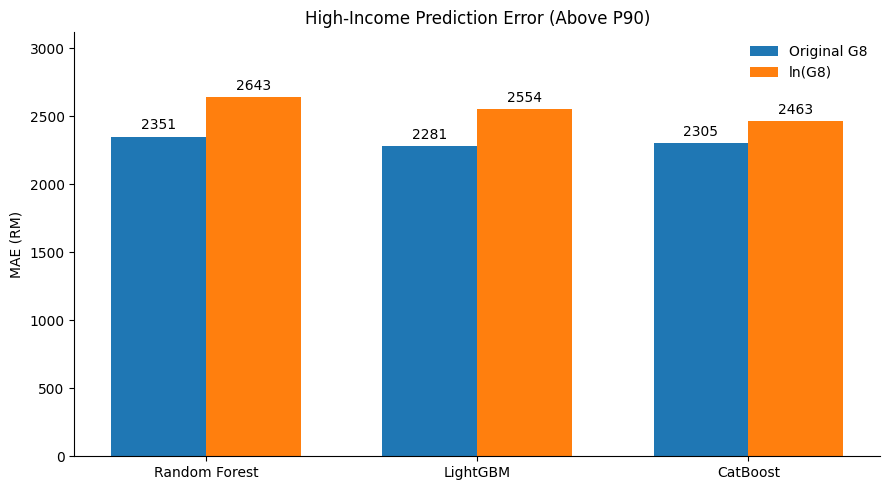

In [38]:

# Step 4.3: High-Income Error Visualization

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Select high-income group (P90+)
plot_data = high_income_models[
    high_income_models["Group"] == "High Income (P90+)"
]

models = [
    "Random Forest",
    "LightGBM",
    "CatBoost"
]

original_mae = []
log_mae = []

for model in models:
    data = plot_data[plot_data["Model"] == model]

    original_mae.append(
        data.loc[
            data["Target"] == "Original G8",
            "MAE"
        ].iloc[0]
    )

    log_mae.append(
        data.loc[
            data["Target"] == "ln(G8)",
            "MAE"
        ].iloc[0]
    )

# Plot
x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width / 2,
    original_mae,
    width,
    label="Original G8"
)

bars2 = ax.bar(
    x + width / 2,
    log_mae,
    width,
    label="ln(G8)"
)

ax.bar_label(bars1, fmt="%.0f", padding=3)
ax.bar_label(bars2, fmt="%.0f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylabel("MAE (RM)")
ax.set_title(
    "High-Income Prediction Error (Above P90)"
)

ax.set_ylim(0, max(log_mae) * 1.18)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "week5_high_income_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [39]:

# Task 5: Final Results
# Step 5.1: Export Key Tables

from pathlib import Path

output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "decision_tree_cv.csv": cv_dt_results,
    "original_model_cv.csv": cv_all_results,
    "original_vs_log_test.csv": final_log_comparison,
    "original_vs_log_cv.csv": final_cv_comparison,
    "additional_metrics.csv": additional_metrics_df,
    "income_group_errors.csv": group_summary,
    "high_income_model_comparison.csv": high_income_models
}

for filename, table in tables.items():
    table.to_csv(
        output_dir / filename,
        index=False
    )
    print("Saved:", filename)

print("\nAll key results exported.")


Saved: decision_tree_cv.csv
Saved: original_model_cv.csv
Saved: original_vs_log_test.csv
Saved: original_vs_log_cv.csv
Saved: additional_metrics.csv
Saved: income_group_errors.csv
Saved: high_income_model_comparison.csv

All key results exported.
